In [3]:
import cantera as ct
import numpy as np 
import pandas as pd

import matplotlib.pyplot as plt

%matplotlib inline

In [ ]:
gas = ct.Solution('gri30.yaml')

gas.TPX = 300, ct.one_atm, 'CH4:1.0, O2:2.0, N2:7.52'

# State
print(f"T, P            : {gas.T:.1f} K, {gas.P:.0f} Pa")
print(f"Mean mol. weight: {gas.mean_molecular_weight:.3f} kg/kmol")
print(f"Equiv. ratio    : {gas.equivalence_ratio():.3f}")

# Thermo (mass basis)
print(f"cp, cv          : {gas.cp_mass:.1f}, {gas.cv_mass:.1f} J/kg/K")
print(f"gamma           : {gas.cp_mass / gas.cv_mass:.4f}")
print(f"h, s            : {gas.enthalpy_mass:.4g} J/kg, {gas.entropy_mass:.4g} J/kg/K")
print(f"Sound speed     : {gas.sound_speed:.1f} m/s")   # available in recent Cantera

# Transport
print(f"Viscosity       : {gas.viscosity:.3e} Pa s")
print(f"Conductivity    : {gas.thermal_conductivity:.4f} W/m/K")
print(f"Thermal diff.   : {gas.thermal_conductivity/(gas.density*gas.cp_mass):.3e} m2/s")


T, P            : 300.0 K, 101325 Pa
Mean mol. weight: 27.633 kg/kmol
Equiv. ratio    : 1.000
cp, cv          : 1077.3, 776.4 J/kg/K
gamma           : 1.3875
h, s            : -2.546e+05 J/kg, 7248 J/kg/K
Sound speed     : 353.9 m/s
Viscosity       : 1.803e-05 Pa s
Conductivity    : 0.0273 W/m/K
Thermal diff.   : 2.255e-05 m2/s


In [19]:
gas = ct.Solution('gri30.yaml')

gas.TPX = 300, ct.one_atm, 'CH4:5.0, O2:2.0, N2:7.52'

# State
print(f"T, P            : {gas.T:.1f} K, {gas.P:.0f} Pa")
print(f"Mean mol. weight: {gas.mean_molecular_weight:.3f} kg/kmol")
print(f"Equiv. ratio    : {gas.equivalence_ratio():.3f}")

# Thermo (mass basis)
print(f"cp, cv          : {gas.cp_mass:.1f}, {gas.cv_mass:.1f} J/kg/K")
print(f"gamma           : {gas.cp_mass / gas.cv_mass:.4f}")
print(f"h, s            : {gas.enthalpy_mass:.4g} J/kg, {gas.entropy_mass:.4g} J/kg/K")
print(f"Sound speed     : {gas.sound_speed:.1f} m/s")   # available in recent Cantera

# Transport
print(f"Viscosity       : {gas.viscosity:.3e} Pa s")
print(f"Conductivity    : {gas.thermal_conductivity:.4f} W/m/K")
print(f"Thermal diff.   : {gas.thermal_conductivity/(gas.density*gas.cp_mass):.3e} m2/s")


T, P            : 300.0 K, 101325 Pa
Mean mol. weight: 24.441 kg/kmol
Equiv. ratio    : 5.000
cp, cv          : 1285.6, 945.4 J/kg/K
gamma           : 1.3598
h, s            : -1.049e+06 J/kg, 8182 J/kg/K
Sound speed     : 372.5 m/s
Viscosity       : 1.637e-05 Pa s
Conductivity    : 0.0294 W/m/K
Thermal diff.   : 2.304e-05 m2/s


In [21]:
gas = ct.Solution('h2o2.yaml')

coeffs= gas.species('H2O2').thermo.coeffs

print(f"H2O high-T coeffs: {coeffs[8:]}")

gas.TPX = 1000, ct.one_atm, "H2O:1"
print(f"h(H2O, 1000K) = {gas.enthalpy_mass / 1e6:.3f} MJ/kg")

H2O high-T coeffs: [ 4.27611269e+00 -5.42822417e-04  1.67335701e-05 -2.15770813e-08
  8.62454363e-12 -1.77025821e+04  3.43505074e+00]
h(H2O, 1000K) = -11.980 MJ/kg


In [22]:
ct.one_atm

101325.0

In [24]:
gas = ct.Solution('gri30.yaml')

phi = 1.0
gas.set_equivalence_ratio(phi, 'CH4', 'O2:1.0, N2:3.76')

gas.TP = 300, ct.one_atm

print(f"Temperature: {gas.T} K")
print(f"Pressure: {gas.P} Pa")
print(f"enthalpy: {gas.enthalpy_mass} J/kg")

Temperature: 300.0 K
Pressure: 101325.00000000001 Pa
enthalpy: -254587.04779300315 J/kg


In [31]:
def X_pct(sp):
    """Mole fraction of species `sp` in percent."""
    return gas.X[gas.species_index(sp)] * 100

In [32]:
T_unburned = gas.T
h_unburned = gas.enthalpy_mass

gas.equilibrate('HP')

print(f"T_unburned : {T_unburned:.1f} K")
print(f"T_ad       : {gas.T:.1f} K")          # adiabatic flame temperature
print(f"CO2        : {X_pct('CO2'):.2f} mol%")
print(f"H2O        : {X_pct('H2O'):.2f} mol%")
print(f"CO         : {X_pct('CO'):.4f} mol%")    # dissociation product
print(f"OH         : {X_pct('OH'):.4f} mol%")    # dissociation product


T_unburned : 2225.5 K
T_ad       : 2225.5 K
CO2        : 8.54 mol%
H2O        : 18.35 mol%
CO         : 0.8988 mol%
OH         : 0.2875 mol%


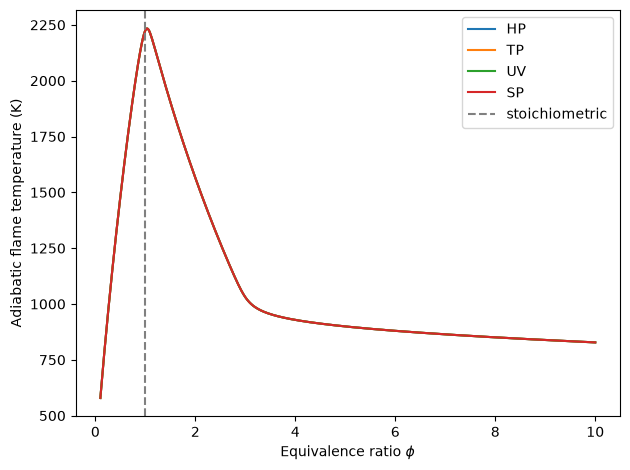

In [43]:
phi_range = np.linspace(0.1, 10.0, 500)
T_ad_HP      = []
T_ad_TP      = []
T_ad_UV      = []
T_ad_SP      = []



for phi in phi_range:
    gas.set_equivalence_ratio(phi, "CH4", "O2:1, N2:3.76")
    gas.TP = 300, ct.one_atm
    gas.equilibrate("HP")
    T_ad_HP.append(gas.T)

    gas.equilibrate("TP")
    T_ad_TP.append(gas.T)

    gas.equilibrate("UV")
    T_ad_UV.append(gas.T)

    gas.equilibrate("SP")
    T_ad_SP.append(gas.T)

plt.plot(phi_range, T_ad_HP, label="HP")
plt.plot(phi_range, T_ad_TP, label="TP")
plt.plot(phi_range, T_ad_UV, label="UV")
plt.plot(phi_range, T_ad_SP, label="SP")
plt.xlabel("Equivalence ratio $\\phi$")
plt.ylabel("Adiabatic flame temperature (K)")
plt.axvline(1.0, ls="--", color="gray", label="stoichiometric")
plt.legend()
plt.tight_layout()

In [ ]:
phi_range = np.linspace(0.1, 10.0, 500)
modes = ["HP", "TP", "UV", "SP"]
T_ad = {m: [] for m in modes}

for phi in phi_range:
    for m in modes:
        gas.set_equivalence_ratio(phi, "CH4", "O2:1, N2:3.76")
        gas.TP = 300, ct.one_atm          # unburned reactants every time
        gas.equilibrate(m)
        T_ad[m].append(gas.T)


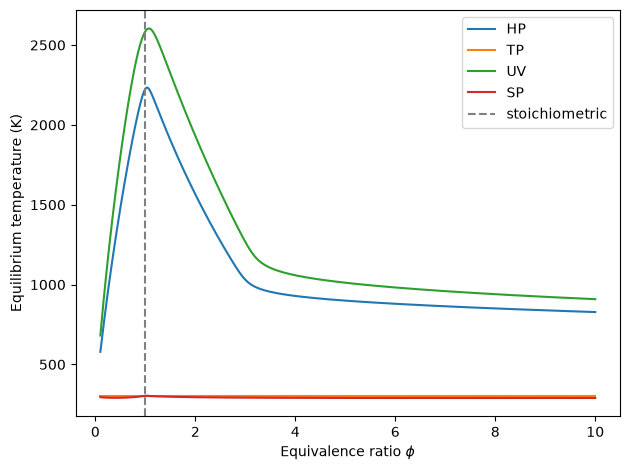

In [46]:
for m in modes:
    plt.plot(phi_range, T_ad[m], label=m)
plt.xlabel("Equivalence ratio $\\phi$")
plt.ylabel("Equilibrium temperature (K)")
plt.axvline(1.0, ls="--", color="gray", label="stoichiometric")
plt.legend()
plt.tight_layout()

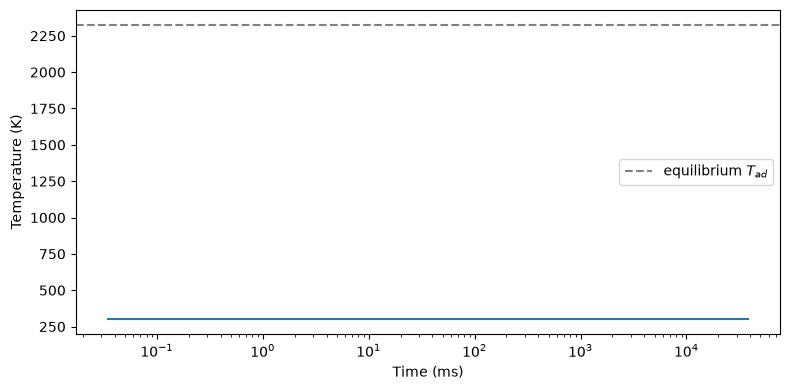

In [86]:
import cantera as ct
import numpy as np
import matplotlib.pyplot as plt

gas = ct.Solution("gri30.yaml")

# Same initial condition as before — stoichiometric CH4/air at 300 K
gas.set_equivalence_ratio(1.0, "CH4", "O2:1, N2:3.76")
gas.TP = 300, ct.one_atm

# Build reactor and integrator
reactor = ct.IdealGasConstPressureReactor(gas,clone=True)
net     = ct.ReactorNet([reactor])

# Integrate forward in time — collecting state at each step
t_end  = 10          # s — long enough to reach equilibrium
states = ct.SolutionArray(gas, extra=["t"])

t = 0.0
while t < t_end:
    t = net.step()
    states.append(reactor.phase.state, t=t)

# Plot temperature evolution
plt.figure(figsize=(8, 4))
plt.semilogx(states.t * 1e3, states.T)   # time axis in ms, log scale
plt.xlabel("Time (ms)")
plt.ylabel("Temperature (K)")
plt.axhline(2326, ls="--", color="gray", label="equilibrium $T_{ad}$")
plt.legend()
plt.tight_layout()

In [88]:
dTdt = np.gradient(states.T,states.t)
tau_ig = states.t[np.argmax(dTdt)]

print(f"Ignition delay  : {tau_ig*1e3:.3f} ms")
print(f"Equilibrium T   : {states.T[-1]:.1f} K")

# Compare with direct equilibrate() result
gas.set_equivalence_ratio(1.0, "CH4", "O2:1, N2:3.76")
gas.TP = 300, ct.one_atm
gas.equilibrate("HP")
print(f"Direct T_ad     : {gas.T:.1f} K")

Ignition delay  : 3775.519 ms
Equilibrium T   : 300.0 K
Direct T_ad     : 2225.5 K


In [87]:
# What does the mixture look like at t = 1 ms? (before ignition)
idx_1ms = np.argmin(np.abs(states.t - 1e-3))
k_CH4 = gas.species_index("CH4")
k_CO  = gas.species_index("CO")

print(f"At t = 1 ms (before ignition):")
print(f"  T   = {states.T[idx_1ms]:.1f} K")
print(f"  CH4 = {states.Y[idx_1ms, k_CH4]*100:.2f} mass%  (unburned fuel)")
print(f"  CO  = {states.Y[idx_1ms, k_CO]*1e6:.1f} ppm")


At t = 1 ms (before ignition):
  T   = 300.0 K
  CH4 = 5.52 mass%  (unburned fuel)
  CO  = 0.0 ppm



************ Solving on 6 point grid with energy equation enabled ************

Attempt Newton solution of steady-state problem.
Newton steady-state solve failed.

Attempt 10 timesteps.
Final timestep info: dt= 8.009e-06  log(ss)= 5.913     

Attempt Newton solution of steady-state problem.
Newton steady-state solve failed.

Attempt 10 timesteps.
Final timestep info: dt= 0.0002053  log(ss)= 5.58      

Attempt Newton solution of steady-state problem.
Newton steady-state solve failed.

Attempt 10 timesteps.
Final timestep info: dt= 0.001039   log(ss)= 4.989     

Attempt Newton solution of steady-state problem.
Newton steady-state solve failed.

Attempt 10 timesteps.
Final timestep info: dt= 0.005918   log(ss)= 4.321     

Attempt Newton solution of steady-state problem.
Newton steady-state solve failed.

Attempt 10 timesteps.
Final timestep info: dt= 0.06741    log(ss)= 1.683     

Attempt Newton solution of steady-state problem.
Newton steady-state solve succeeded.

Problem solved on

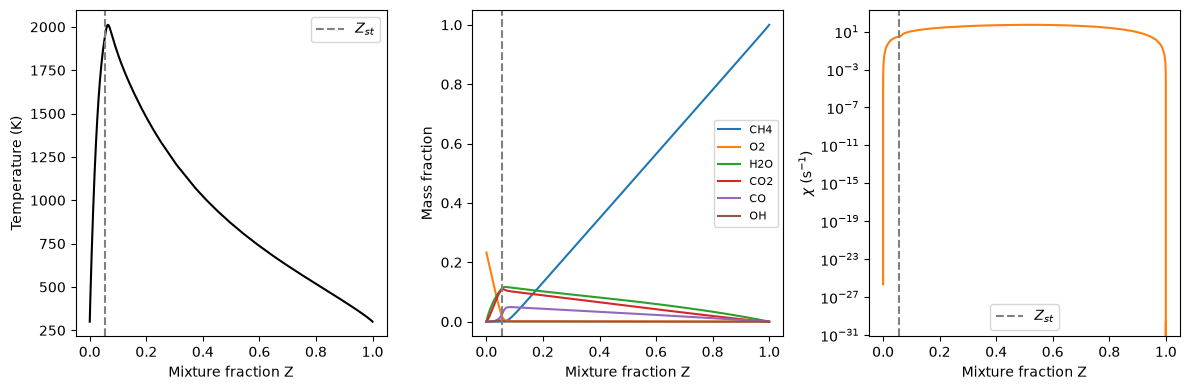

In [90]:
# ── Setup ──────────────────────────────────────────────────────────────────
gas = ct.Solution("gri30.yaml")

width   = 0.02       # m — domain width between the two nozzles
T_fuel  = 300.0      # K
T_ox    = 300.0      # K
mdot_f  = 0.24       # kg/(m²·s)
mdot_ox = 0.72       # kg/(m²·s)

flame = ct.CounterflowDiffusionFlame(gas, width=width)
flame.fuel_inlet.mdot     = mdot_f
flame.fuel_inlet.X        = "CH4:1"
flame.fuel_inlet.T        = T_fuel
flame.oxidizer_inlet.mdot = mdot_ox
flame.oxidizer_inlet.X    = "O2:0.21, N2:0.79"
flame.oxidizer_inlet.T    = T_ox

# ── Solve ──────────────────────────────────────────────────────────────────
flame.set_refine_criteria(ratio=3, slope=0.1, curve=0.2)
flame.solve(loglevel=1, auto=True)

# ── Post-processing ────────────────────────────────────────────────────────
x   = flame.grid                              # m
Z   = flame.mixture_fraction("Bilger")        # 1 at fuel side, 0 at oxidiser side

# Scalar dissipation rate: χ = 2 D |dZ/dx|², with D = k/(ρ c_p) (Le = 1)
D   = flame.thermal_conductivity / (flame.density * flame.cp_mass)
chi = 2 * D * np.gradient(Z, x)**2

# Stoichiometric mixture fraction for CH4 + 2 O2, with air at Y_O2 = 0.233
W_O2, W_N2, W_CH4 = 31.998, 28.014, 16.043
Y_O2 = 0.21*W_O2 / (0.21*W_O2 + 0.79*W_N2)
s    = 2*W_O2 / W_CH4                         # mass of O2 per mass of CH4
Z_st = 1 / (1 + s / Y_O2)

# Z decreases along x, so sort before interpolating
o      = np.argsort(Z)
chi_st = np.interp(Z_st, Z[o], chi[o])

a = flame.strain_rate("max")                  # max |du/dx|

print(f"Strain rate a     = {a:.1f} s⁻¹")
print(f"Z_st              = {Z_st:.4f}")
print(f"χ_st (at Z_st)    = {chi_st:.2f} s⁻¹")
print(f"T_max             = {flame.T.max():.1f} K")

# ── Plot ───────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

axes[0].plot(Z, flame.T, "k")
axes[0].axvline(Z_st, ls="--", color="gray", label="$Z_{st}$")
axes[0].set_xlabel("Mixture fraction Z")
axes[0].set_ylabel("Temperature (K)")
axes[0].legend()

for sp in ["CH4", "O2", "H2O", "CO2", "CO", "OH"]:
    axes[1].plot(Z, flame.Y[gas.species_index(sp)], label=sp)
axes[1].axvline(Z_st, ls="--", color="gray")
axes[1].set_xlabel("Mixture fraction Z")
axes[1].set_ylabel("Mass fraction")
axes[1].legend(fontsize=8)

axes[2].semilogy(Z, chi, "C1")
axes[2].axvline(Z_st, ls="--", color="gray", label="$Z_{st}$")
axes[2].set_xlabel("Mixture fraction Z")
axes[2].set_ylabel(r"$\chi$ (s$^{-1}$)")
axes[2].legend()

plt.tight_layout()
